Notebook goals:

- Get some nice plots displaying the Bauder sn dataset

In [1]:
import warnings
import os 
from pathlib import Path

import pandas as pd
import scanpy as sc
import numpy as np
from dotenv import dotenv_values
from matplotlib import pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter, PercentFormatter
from matplotlib.patches import Patch

warnings.simplefilter(action='ignore', category=FutureWarning)
sc.set_figure_params(frameon=False, dpi=120, figsize=(5, 5))

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Ext_Fig_05"
os.makedirs(OUTDIR, exist_ok=True)

SC_IN_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_control.h5ad'

In [3]:
adata = sc.read_h5ad(SC_IN_FP, backed="r")

In [4]:
bauder_cells = adata[adata.obs.Author == "BauderC"].to_memory()
adata.obs["Bauder_sn_cells"] = False
adata.obs.loc[adata.obs.Dataset == "SC2-19", "Bauder_sn_cells"] = True

In [5]:
l1_colors = {
    'Gl1-1 Glut': "#8c564b",
    'Gb1-2 GABA': "#aa40fc",
    'NN1-4 Astro-Epen': "#17becf",
    'NN1-1 OPC-Oligo': "#ffbb78",
    'NN1-2 Immune': "#aec7e8",
    'NN1-3 Vascular': "#98df8a" 
}

# Bar plots

## Top 10 datasets

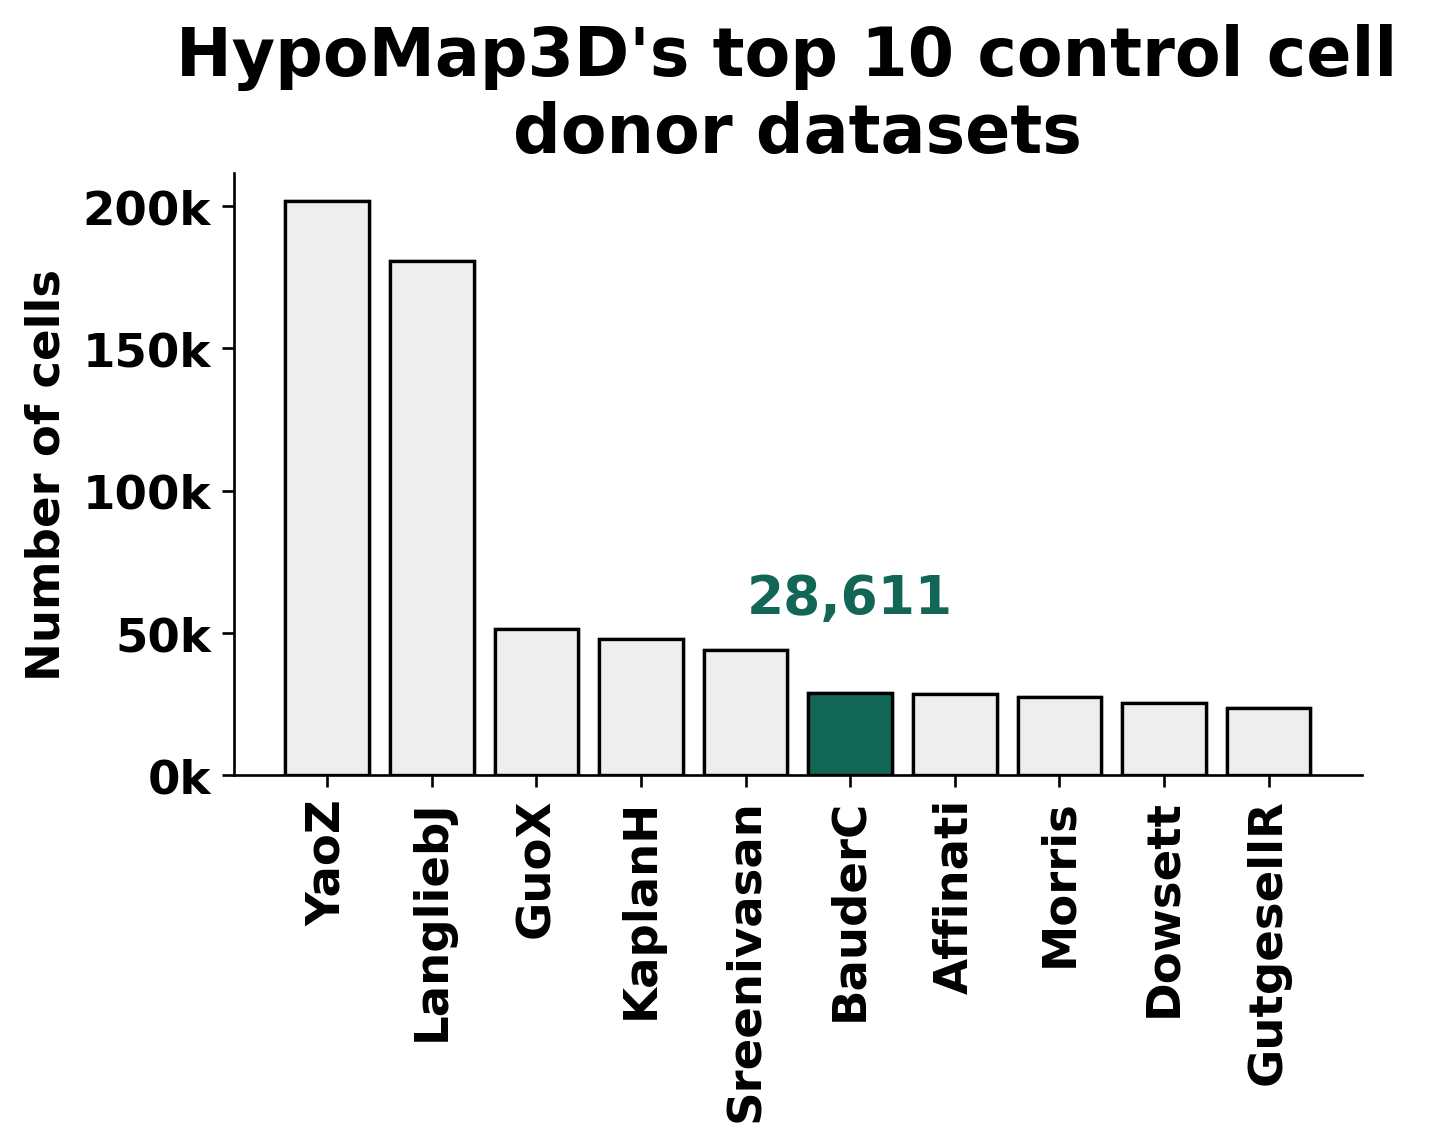

In [13]:
# Top 10 authors
counts = adata.obs["Author"].value_counts().head(10)

# Colors: highlight BauderC
colors = [
    "#116656" if author == "BauderC" else "#EEEEEE"
    for author in counts.index
]

fig, ax = plt.subplots(figsize=(6, 5))

ax.bar(
    counts.index,
    counts.values,
    color=colors,
    edgecolor="black",
    linewidth=1,
)

ax.set_ylabel("Number of cells", fontweight="bold")
ax.set_xlabel("")
ax.set_title("HypoMap3D's top 10 control cell \ndonor datasets", fontweight="bold", fontsize=20)
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x/1000:g}k")
)


bars = ax.bar(
    counts.index,
    counts.values,
    color=colors,
    edgecolor="black",
    linewidth=1,
)

for bar, author, value in zip(bars, counts.index, counts.values):
    if author == "BauderC":
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + counts.max() * 0.12,
            f"{value:,}",         
            ha="center",
            va="bottom",
            fontsize=16,
            fontweight="bold",
            color="#116656",
            #rotation=90
        )

# Make tick labels bold
for label in ax.get_xticklabels():
    label.set_fontweight("bold")

for label in ax.get_yticklabels():
    label.set_fontweight("bold")

# Clean up
sns.despine(ax=ax)
ax.grid(False)

# Rotate labels if needed
ax.tick_params(axis="x", rotation=90)

plt.tight_layout()

# Save as vector 
plt.savefig(OUTDIR / "top_10_largest.pdf", format="pdf", dpi=300, bbox_inches="tight")

plt.show()

## QC metrics per sample

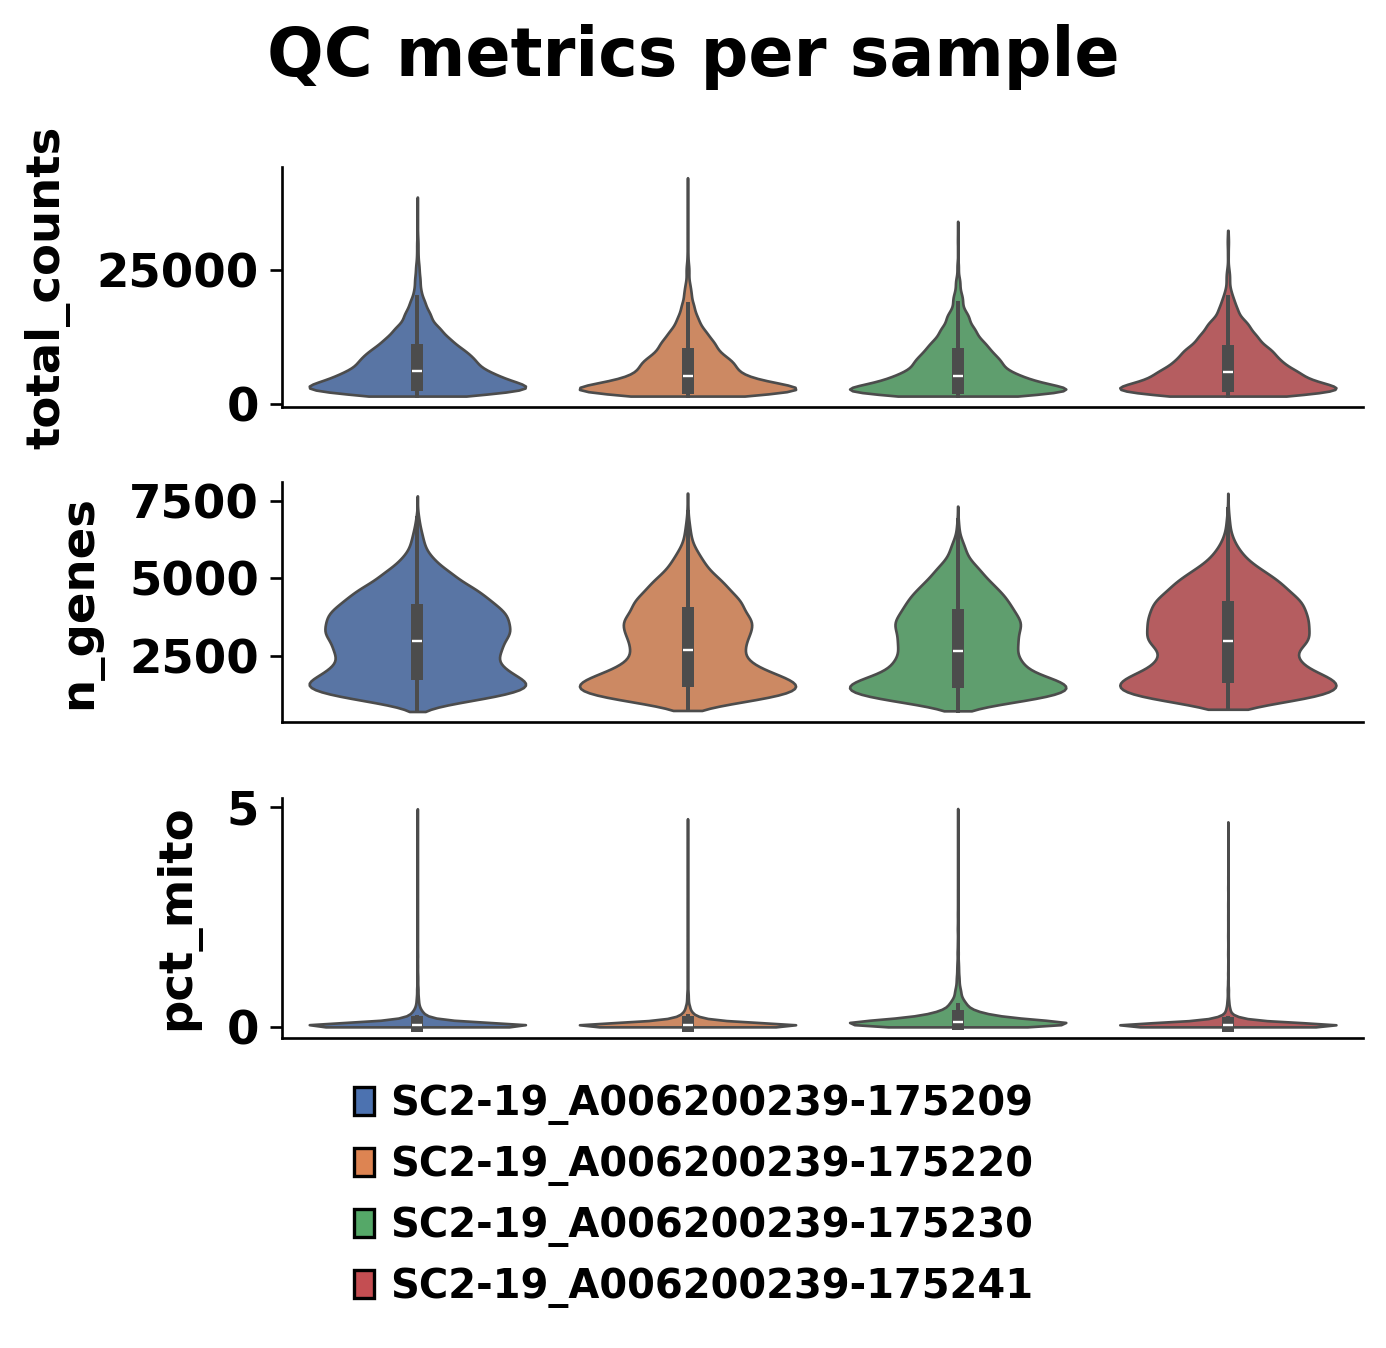

In [12]:


# Variables to plot
vars_to_plot = ["total_counts", "n_genes", "pct_mito"]

# Extract data
df = bauder_cells.obs[["Sample"] + vars_to_plot].copy()

# Sample order
sample_order = ['SC2-19_A006200239-175209', 'SC2-19_A006200239-175220', 'SC2-19_A006200239-175230', 'SC2-19_A006200239-175241']  

# Define your own colors
palette = {
    "SC2-19_A006200239-175209": "#4C72B0",  # blue
    "SC2-19_A006200239-175220": "#DD8452",  # orange
    "SC2-19_A006200239-175230": "#55A868",  # green
    "SC2-19_A006200239-175241": "#C44E52",  # red
}

# Figure
fig, axes = plt.subplots(
    3, 1,
    figsize=(6, 5),
    sharex=True
)

for ax, var in zip(axes, vars_to_plot):
    sns.violinplot(
        data=df,
        x="Sample",
        y=var,
        hue="Sample",
        order=sample_order,
        palette=palette,
        legend=False,
        cut=0,
        linewidth=0.8,
        ax=ax,
    )

    # Clean up
    sns.despine(ax=ax)
    ax.grid(False)
    ax.set_xlabel("")
    ax.set_ylabel(var, labelpad=8, fontweight="bold")

    # Make tick labels bold
    for label in ax.get_yticklabels():
        label.set_fontweight("bold")

# Remove all x-axis ticks completely
for ax in axes:
    ax.tick_params(axis="x", bottom=False)



# Remove x tick labels from all panels (including the last one)
axes[-1].set_xticklabels([])
axes[-1].tick_params(axis="x", length=0)

# Figure legend 
handles = [
    Patch(facecolor=palette[s], edgecolor="black", label=s)
    for s in sample_order
]

fig.legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=1,         
    frameon=False,
    prop={"weight": "bold", "size": 12}
    #title="Sample"
)
fig.suptitle(
    "QC metrics per sample",
    fontsize=20,
    fontweight="bold",
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

# Save as vector 
plt.savefig(OUTDIR / "Bauder_qc_metrics.pdf", format="pdf", dpi=300, bbox_inches="tight")

plt.show()

## L1 class % 

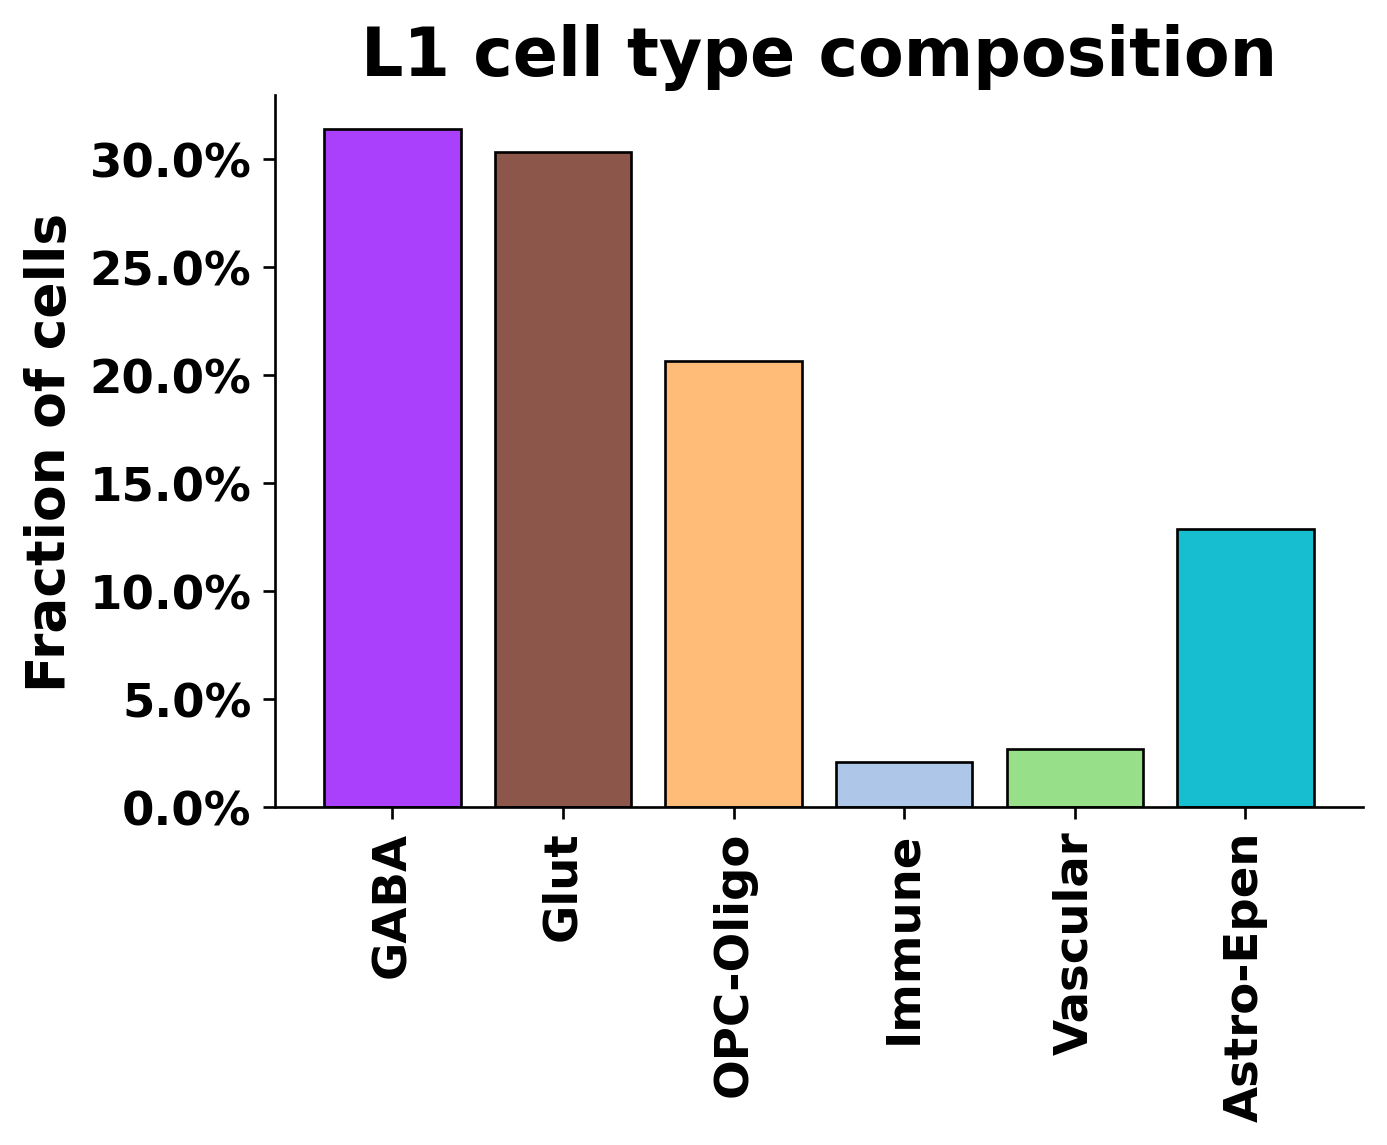

In [11]:

# Calculate proportions
ratios = (
    bauder_cells.obs["L1_descr"]
    .value_counts(normalize=True)
    .sort_index()          # or remove this to sort by frequency
)

# Colors corresponding to each cell type
colors = [l1_colors[celltype] for celltype in ratios.index]

# Plot
fig, ax = plt.subplots(figsize=(6, 5))

bars = ax.bar(
    ratios.index,
    ratios.values,
    color=colors,
    edgecolor="black",
    linewidth=0.8,
)

# Labels and title
ax.set_ylabel("Fraction of cells", fontweight="bold", fontsize=16)
ax.set_xlabel("", fontweight="bold")
ax.set_title("L1 cell type composition", fontweight="bold", fontsize=20)

# Show percentages on y-axis
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

# Make all tick labels bold
plt.setp(ax.get_yticklabels(), fontweight="bold")
# Keep only the second part of each label
new_labels = [label.split(" ", 1)[1] for label in ratios.index]

ax.set_xticks(range(len(new_labels)))
ax.set_xticklabels(
    new_labels,
    rotation=90,
    fontweight="bold",
    ha="center",
)

# Clean up
sns.despine(ax=ax)
ax.grid(False)

plt.tight_layout()


# Save
plt.savefig(
    OUTDIR / "L1_descr_celltype_ratios.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## L2 enrichment

In [9]:

filter_NN = True
target = "BauderC"
################################
######## Get Sample percentages 
################################

# Count cells per cell type and sample
counts = (
    bauder_cells.obs
    .groupby(["L2_descr", "Sample"])
    .size()
    .unstack(fill_value=0)
)

# Convert to % of ALL BauderC cells
percent = counts / len(bauder_cells) * 100

# Optional: sort by overall abundance
percent = percent.loc[percent.mean(axis=1).sort_values().index]

# Reorder columns
percent = percent[sample_order]

################################
######## Get Cell type proprtions 
################################

# sample x cell type counts
counts = (
    adata.obs
    .groupby(["Sample", "L2_descr"])
    .size()
    .unstack(fill_value=0)
)

# convert to proportions
props = counts.div(counts.sum(axis=1), axis=0)

# map samples to authors
sample_author = (
    adata.obs[["Sample", "Author"]]
    .drop_duplicates()
    .set_index("Sample")["Author"]
)

props["Author"] = sample_author.loc[props.index] 

################################
######## Get Z scores
################################
results = []

celltypes = props.columns.drop("Author")

for ct in celltypes:

    x = props.loc[props.Author == target, ct]
    y = props.loc[props.Author != target, ct]

    mean_target = x.mean()
    mean_other = y.mean()
    sd_other = y.std(ddof=1)

    z = (mean_target - mean_other) / sd_other if sd_other > 0 else np.nan

    log2fc = np.log2((mean_target + 1e-6) / (mean_other + 1e-6))

    results.append({
        "cell_type": ct,
        "mean_target": mean_target,
        "mean_other": mean_other,
        "zscore": z,
        "log2FC": log2fc,
        "n_target": len(x),
        "n_other": len(y),
    })

results = (
    pd.DataFrame(results)
    .sort_values("zscore", ascending=False)
)


if filter_NN:
    percent = percent[~percent.index.str.startswith("NN")]
    results = results[~results.cell_type.str.startswith("NN")]


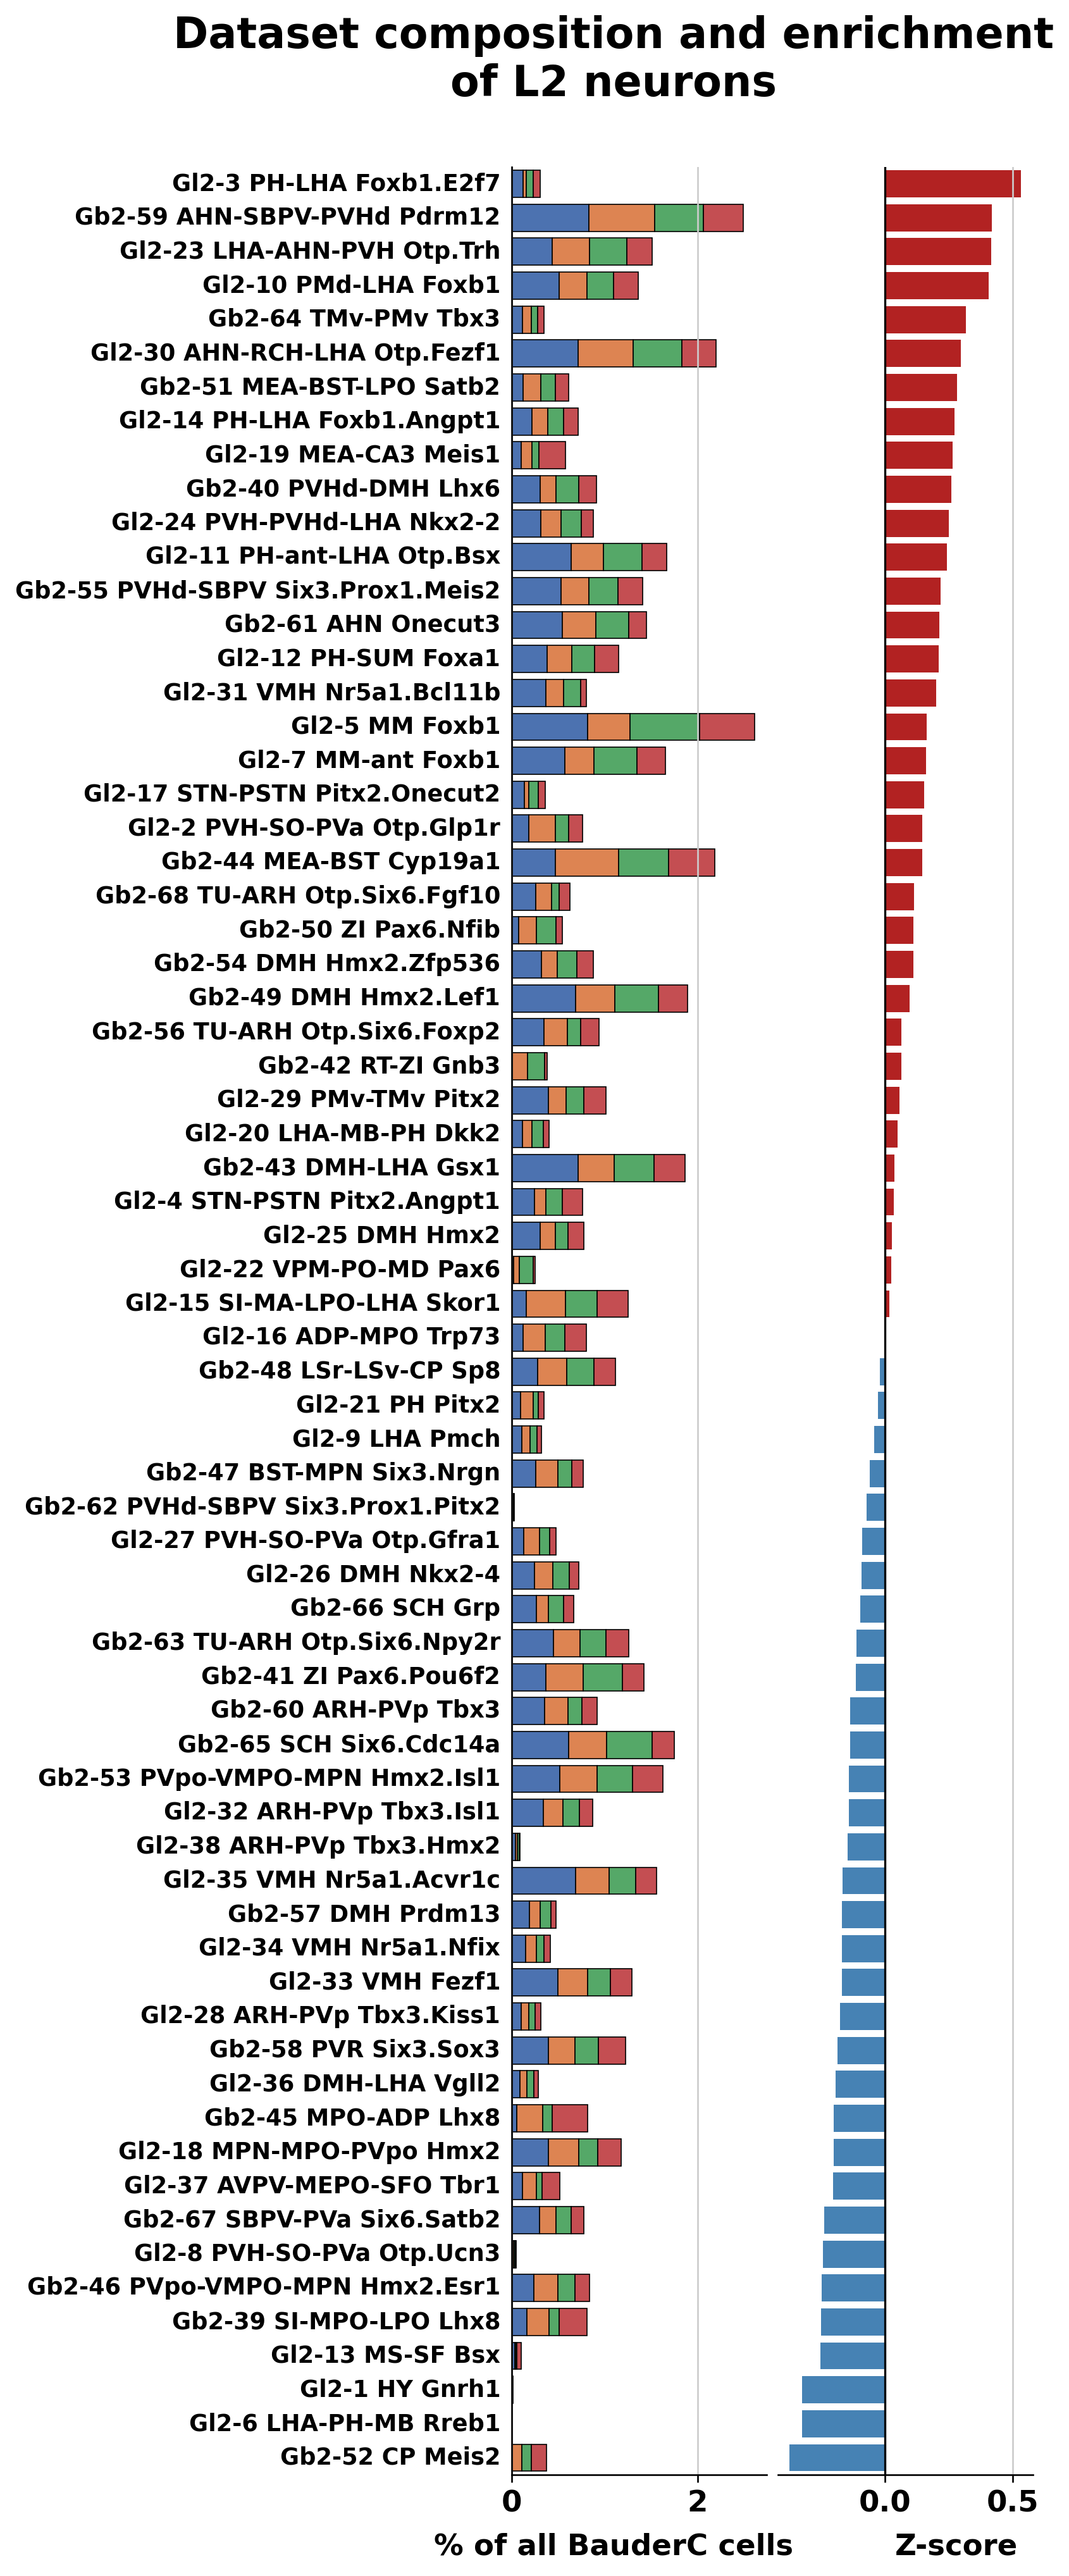

In [10]:

fig = plt.figure(figsize=(6, 20))
gs = fig.add_gridspec(
    1, 3,
    width_ratios=[1.4, 2, 2],
    wspace=0.05
)

ax_labels = fig.add_subplot(gs[0, 0])
ax_comp   = fig.add_subplot(gs[0, 1], sharey=ax_labels)
ax_z      = fig.add_subplot(gs[0, 2], sharey=ax_labels)

# choose an ordering
order = results.sort_values("zscore")["cell_type"]

percent = percent.reindex(order)
plot = results.set_index("cell_type").loc[order]

ax_labels.set_xlim(0, 1)
ax_labels.set_ylim(-0.5, len(order) - 0.5)

for i, ct in enumerate(order):
    ax_labels.text(
        1.0,
        i,
        ct,
        ha="right",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

ax_labels.axis("off")

y = np.arange(len(order))
left = np.zeros(len(order))

for sample in sample_order:
    values = percent[sample].values

    ax_comp.barh(
        y,
        values,
        left=left,
        height=0.8,          
        color=palette[sample],
        edgecolor="black",
        linewidth=0.5,
    )

    left += values

ax_comp.set_yticks([])
ax_comp.set_ylim(-0.5, len(order)-0.5)

ax_comp.set_xlabel("% of all BauderC cells", fontweight="bold")
ax_comp.xaxis.set_label_coords(0.4, -0.025)
sns.despine(ax=ax_comp)

colors = np.where(plot["zscore"] > 0,
                  "firebrick",
                  "steelblue")

ax_z.barh(
    y,
    plot["zscore"],
    height=0.8,
    color=colors,
)
ax_z.set_ylim(-0.5, len(order)-0.5)
ax_z.axvline(0, color="black", lw=1)
ax_z.set_yticks([])
ax_z.set_xlabel("Z-score", fontweight="bold")
ax_z.xaxis.set_label_coords(0.7, -0.025)

# bold tick labels
plt.setp(ax_comp.get_xticklabels(), fontweight="bold")
plt.setp(ax_z.get_xticklabels(), fontweight="bold")

sns.despine(ax=ax_z, left=True)

fig.suptitle(
    "Dataset composition and enrichment\nof L2 neurons",
    fontsize=20,
    fontweight="bold",
    y=0.96,  
)

plt.savefig(OUTDIR /  "L2_cell_ratios.pdf", format="pdf", dpi=300, bbox_inches="tight")

# UMAPs

## Bauder cells within HM3D umap

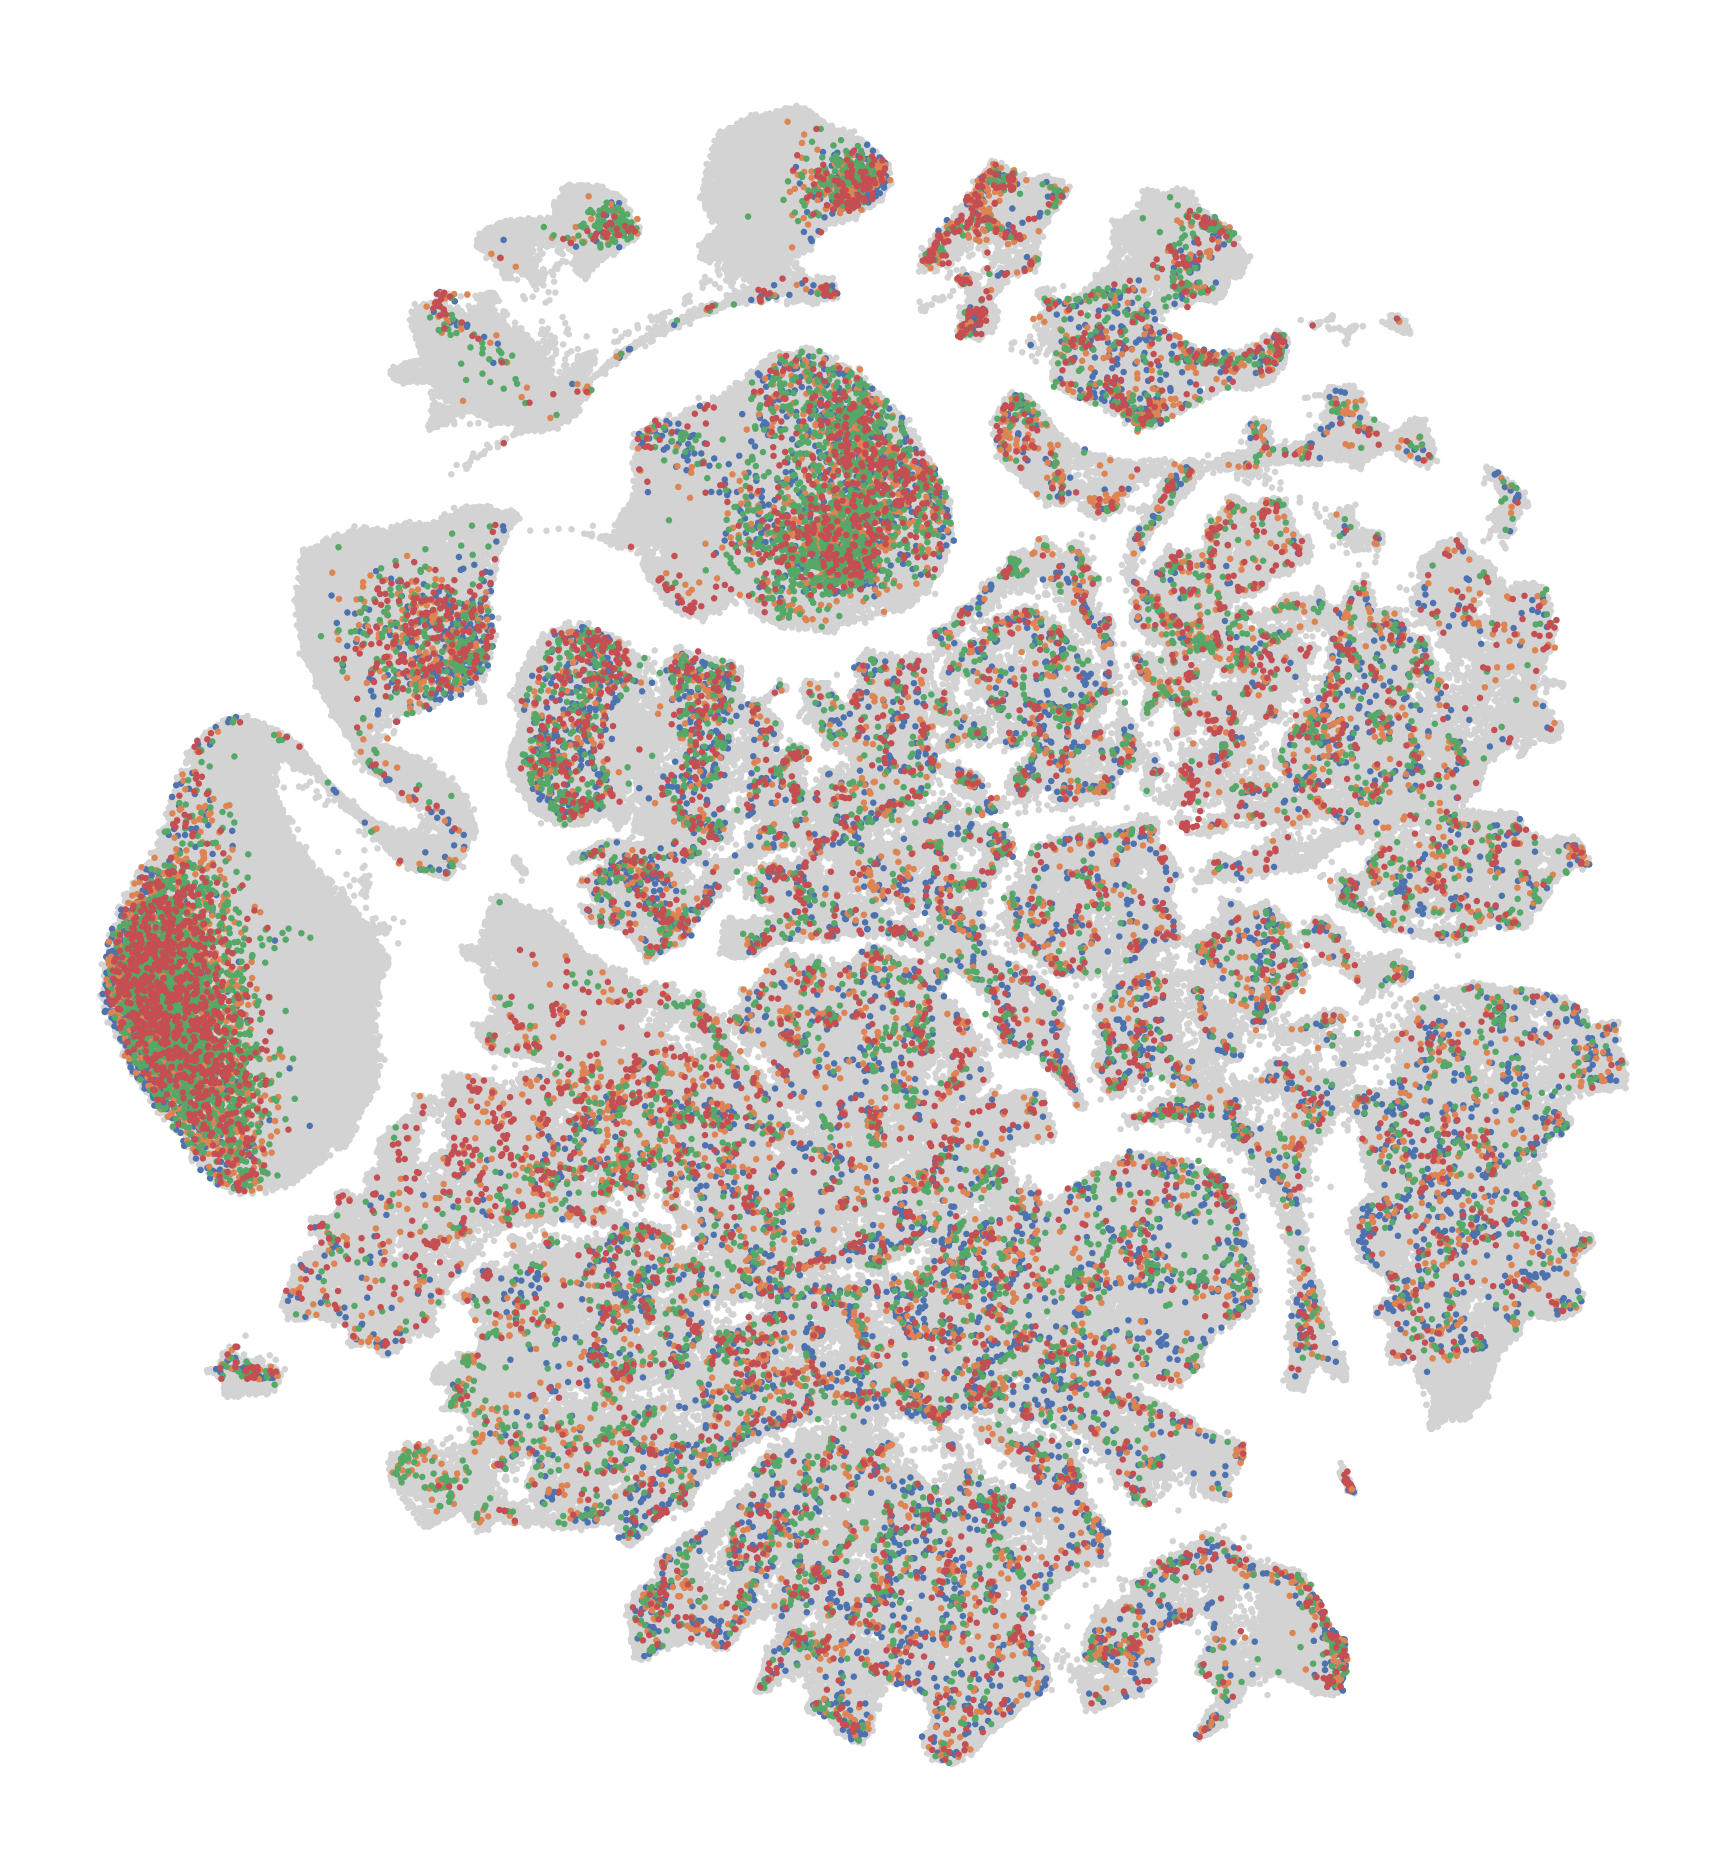

In [12]:
scattersize=15

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(10, 10))

# 1. Plot SC cells in gray
sc.pl.umap(
    adata,
    color="L1_descr",  
    ax=ax,
    show=False,
    palette=["lightgrey"], 
    s=scattersize,
    legend_loc=None
)

# 2. Plot Bauder cells with actual palette
sc.pl.umap(
    bauder_cells,
    color="Sample",
    palette=palette,  # Your color dict
    ax=ax,
    show=False,
    s=scattersize,
    legend_loc=None
)

# Rasterize all scatter points (collections are added to ax.collections in order)
for coll in ax.collections:
    coll.set_rasterized(True)

# Clean up plot appearance
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

# Save as vector with rasterized scatter points
plt.savefig(OUTDIR /  "Bauder_in_hm3d_umap_sample.pdf", format="pdf", dpi=300, bbox_inches="tight")

## Bauder in own umap


In [13]:
sc.pp.neighbors(bauder_cells, use_rep="X_embed", n_neighbors=15)
sc.tl.umap(bauder_cells)

### Colored by Sample

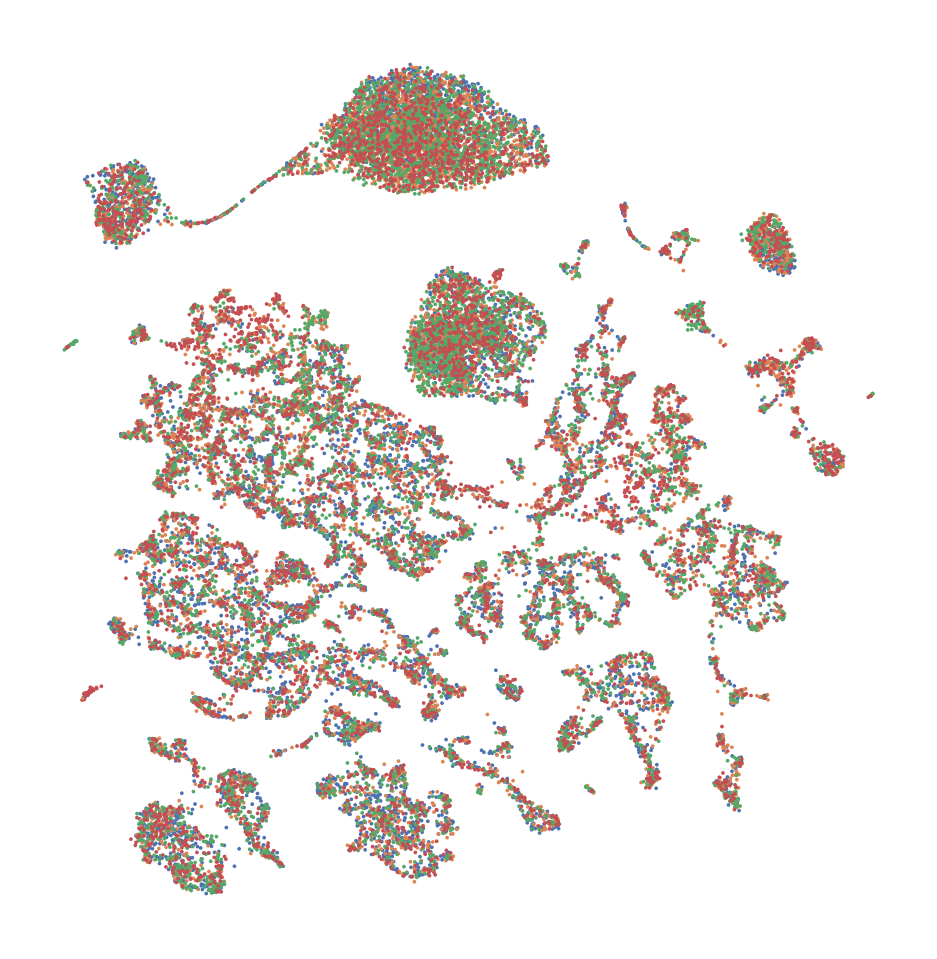

In [14]:
scattersize=5

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(5, 5))

sc.pl.umap(
    bauder_cells,
    color="Sample",
    palette=palette,  # Your color dict
    ax=ax,
    show=False,
    s=scattersize,
    legend_loc=None
)

# Rasterize all scatter points (collections are added to ax.collections in order)
for coll in ax.collections:
    coll.set_rasterized(True)

# Clean up plot appearance
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

# Save as vector with rasterized scatter points
plt.savefig(OUTDIR /  "Bauder_umap_sample.pdf", format="pdf", dpi=300, bbox_inches="tight")

### Colored by L1

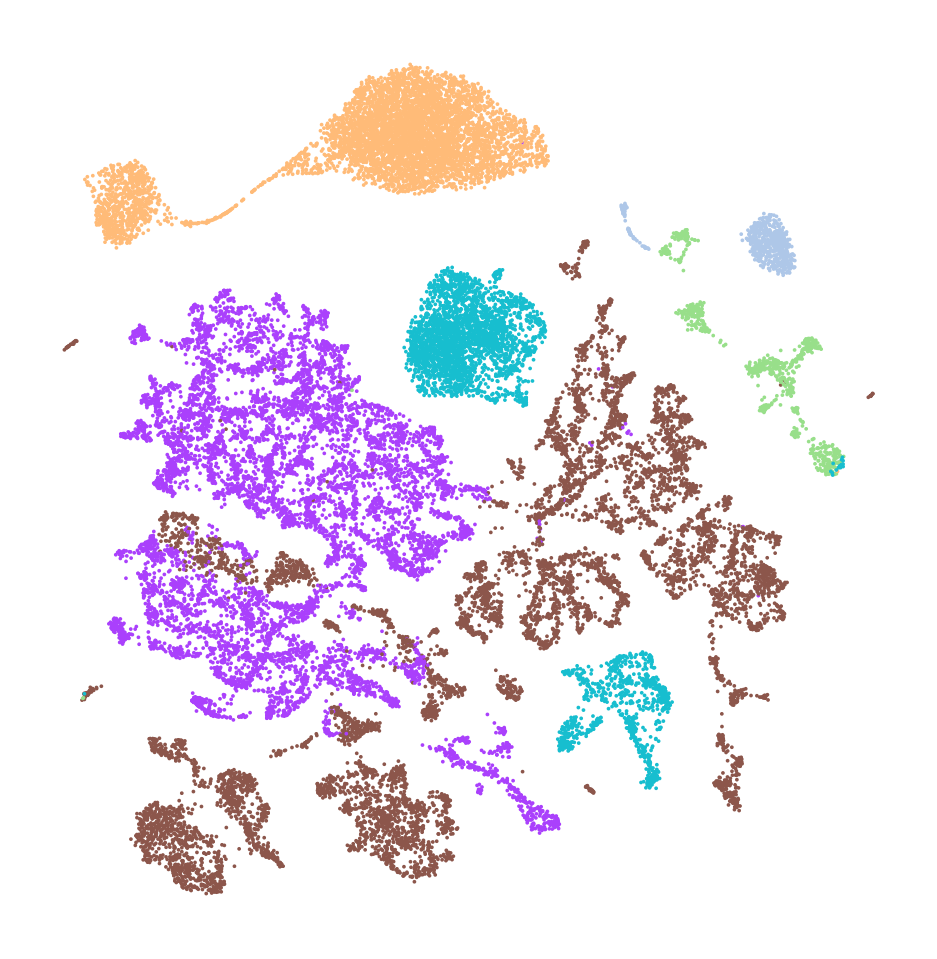

In [15]:
scattersize=5

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(5, 5))

sc.pl.umap(
    bauder_cells,
    color="L1_descr",
    palette=l1_colors, 
    ax=ax,
    show=False,
    s=scattersize,
    legend_loc=None
)

# Rasterize all scatter points (collections are added to ax.collections in order)
for coll in ax.collections:
    coll.set_rasterized(True)

# Clean up plot appearance
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

# legend = ax.get_legend()

# if legend is not None:
#     for text in legend.get_texts():
#         text.set_fontweight("bold")

fig.canvas.draw()

# Save as vector with rasterized scatter points
plt.savefig(OUTDIR /  "Bauder_umap_l1.pdf", format="pdf", dpi=300, bbox_inches="tight")

### Colored by region umbrella

In [16]:
bauder_cells.obs["region"] = bauder_cells.obs.L3_descr.apply(lambda x: x.split(" ")[1] if "NN" not in x else "NN")

bauder_cells.obs["region_umbrella"] = bauder_cells.obs.region.astype(str).copy() 

umbrella_dict = {
    "Mammillary regions": ["MMl", "MMm", "MMme","TMv", "PMv", "SUM", "LM", "PMd"],
    "PVH region": ["PVH", "PVHd", "PVH-SO"],
    "Basal HY": ["ARH", "VMH", "TU"],
    "Dorsal-lateral HY": ["LHA", "DMH"],
    "Anterior HY": ["AHN", "SBPV", "PVi",],
    "Preoptic HY": ["LPO", "MEPO", "MPO", "MPN", "PS", "PVpo", "AVPV" ],
    "ZI/Subthalamic": ["PSTN", "STN", "ZI"],
    "Extra-hypothalamic": ["BST", "CP", "LSr", "LSv", "MB", "MEA", "NDB", "RT", "VAL", "VPM", "SI", "MS"],
    "Posterior HY": ["PH", "PVp", ],
    "HY (Gnrh1 neurons)": ["HY"]
}

for k, v in umbrella_dict.items():
    bauder_cells.obs.loc[bauder_cells.obs.region_umbrella.isin(v), "region_umbrella"] = k

bauder_cells.obs.loc[bauder_cells.obs.region_umbrella == "NN", "region_umbrella"] = "Non-neuronal cells"

bauder_cells.obs["region_umbrella"].unique()

array(['Mammillary regions', 'Dorsal-lateral HY', 'Preoptic HY',
       'Basal HY', 'Anterior HY', 'ZI/Subthalamic', 'PVH region',
       'Extra-hypothalamic', 'Posterior HY', 'SCH', 'HY (Gnrh1 neurons)',
       'Non-neuronal cells'], dtype=object)

In [18]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Get the categories in the order Scanpy will use
categories = bauder_cells.obs["region_umbrella"].astype("category").cat.categories

# Initialize colors from tab20
tab20 = plt.get_cmap("tab20")
umbrella_colors = {
    cat: mcolors.to_hex(tab20(i % 20))
    for i, cat in enumerate(categories)
}
# Overwrite selected categories
umbrella_colors["Non-neuronal cells"] = "lightgrey"
umbrella_colors["HY (Gnrh1 neurons)"] = "purple"
umbrella_colors["Extra-hypothalamic"] = "red"
umbrella_colors["Basal HY"] = "saddlebrown"
umbrella_colors["SCH"] = "cyan"

In [19]:
umbrella_colors

{'Anterior HY': '#1f77b4',
 'Basal HY': 'saddlebrown',
 'Dorsal-lateral HY': '#ff7f0e',
 'Extra-hypothalamic': 'red',
 'HY (Gnrh1 neurons)': 'purple',
 'Mammillary regions': '#98df8a',
 'Non-neuronal cells': 'lightgrey',
 'PVH region': '#ff9896',
 'Posterior HY': '#9467bd',
 'Preoptic HY': '#c5b0d5',
 'SCH': 'cyan',
 'ZI/Subthalamic': '#c49c94'}

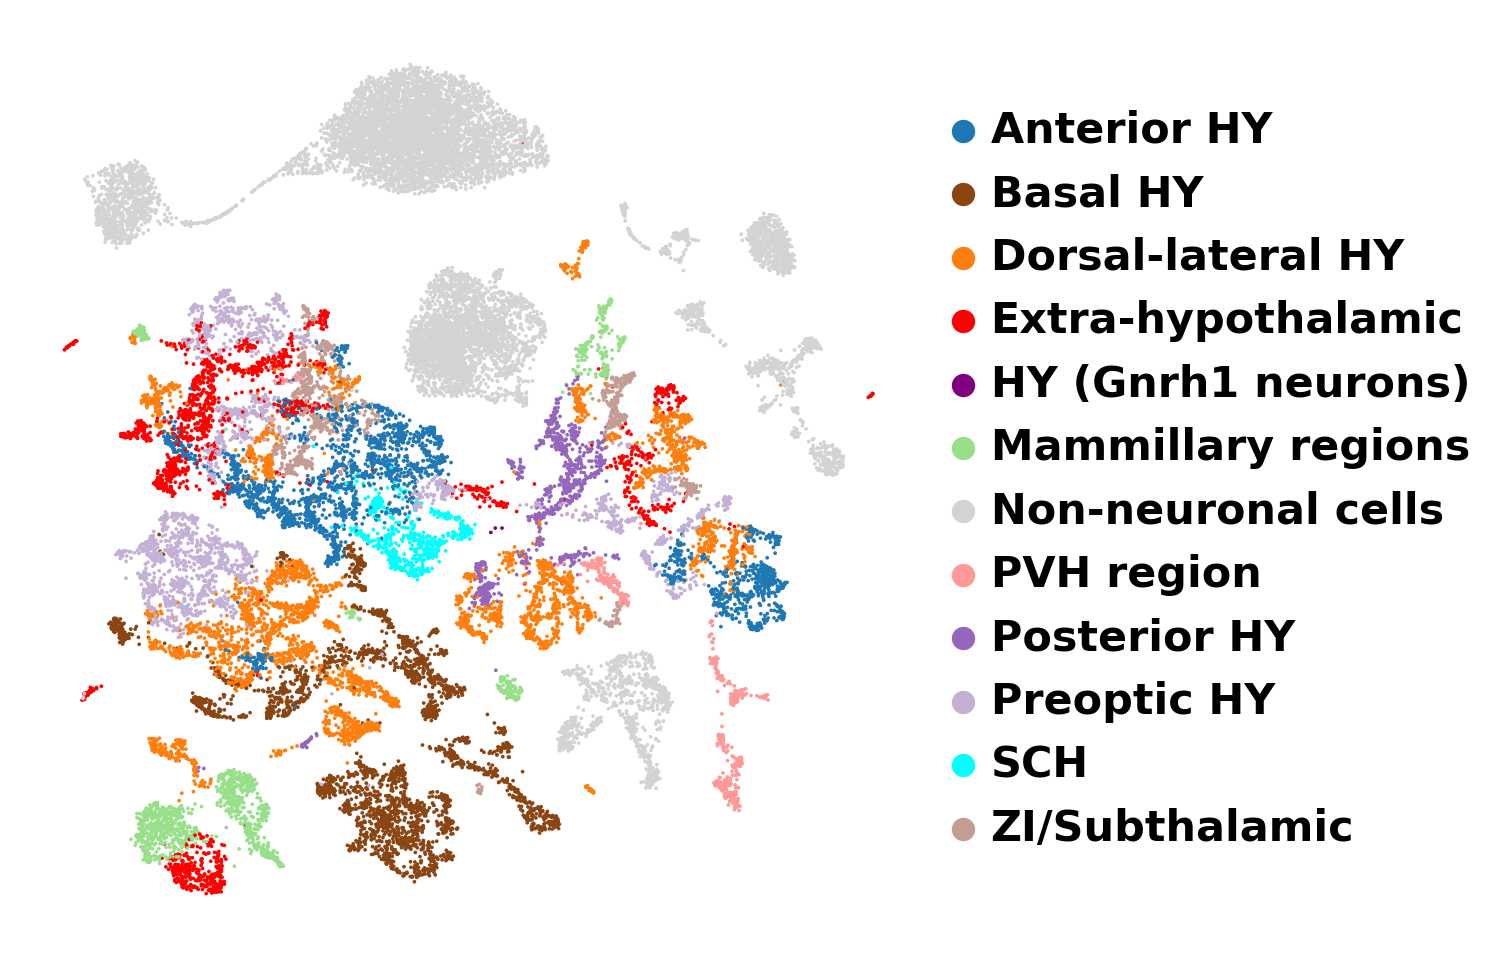

In [20]:
scattersize=5

# Create a high-DPI figure and axis
fig, ax = plt.subplots(figsize=(5, 5))

sc.pl.umap(
    bauder_cells,
    color="region_umbrella",
    palette=umbrella_colors, 
    ax=ax,
    show=False,
    s=scattersize,
    na_color="lightgrey"
    #legend_loc=None
)

# Rasterize all scatter points (collections are added to ax.collections in order)
for coll in ax.collections:
    coll.set_rasterized(True)

# Clean up plot appearance
ax.set_title("")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_aspect('equal')

fig.canvas.draw()

legend = ax.get_legend()

if legend is not None:
    for text in legend.get_texts():
        text.set_fontweight("bold")

# Save as vector with rasterized scatter points
plt.savefig(OUTDIR /  "Bauder_umap_region_umbrella.pdf", format="pdf", dpi=300, bbox_inches="tight")